In [129]:
# ⭐ Project 4: Spam Email Detection - SVM

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

data = pd.read_csv("spam.csv")
df1 = pd.DataFrame(data)
df = df1.copy()
df

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [ ]:
# EDA process
df["Category"] = df["Category"].map({"ham":"not spam","spam":"spam"})
print(df)
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())

      Category                                            Message
0     not spam  Go until jurong point, crazy.. Available only ...
1     not spam                      Ok lar... Joking wif u oni...
2         spam  Free entry in 2 a wkly comp to win FA Cup fina...
3     not spam  U dun say so early hor... U c already then say...
4     not spam  Nah I don't think he goes to usf, he lives aro...
...        ...                                                ...
5567      spam  This is the 2nd time we have tried 2 contact u...
5568  not spam               Will ü b going to esplanade fr home?
5569  not spam  Pity, * was in mood for that. So...any other s...
5570  not spam  The guy did some bitching but I acted like i'd...
5571  not spam                         Rofl. Its true to its name

[5572 rows x 2 columns]
(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------

In [ ]:
# Model Train Test Split
x = df["Message"].values
y = df["Category"].values

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=42)

model_cv = CountVectorizer()
x_train = model_cv.fit_transform(x_train)
x_test = model_cv.transform(x_test)

In [ ]:
model = SVC(kernel = "rbf")
model.fit(x_train,y_train)


SVC()

In [ ]:
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test,y_pred)

print("The model Prediction :",y_pred)
print(f"The model Accuracy:{accuracy*100:.2f}")


The model Prediction : ['not spam' 'not spam' 'not spam' ... 'not spam' 'not spam' 'not spam']
The model Accuracy:98.48


In [ ]:
new_mail = (input("Enter the new mail : "))
new_mail_cv = model_cv.transform([new_mail])
y_pred = model.predict(new_mail_cv)
#print("The new mail is :",y_pred[0])
if y_pred[0] == "spam":
    print("*"*23)
    print("  The Mail is spam 🛑")
    print("*"*23)
else:
    print("*"*27)
    print("  The Mail is not spam ✅")
    print("*"*27)

Enter the new mail : Hi Kavi, are we meeting for python project tomorrow?
***************************
  The Mail is not spam ✅
***************************


Text(0.5, 1.0, 'Pie chart')

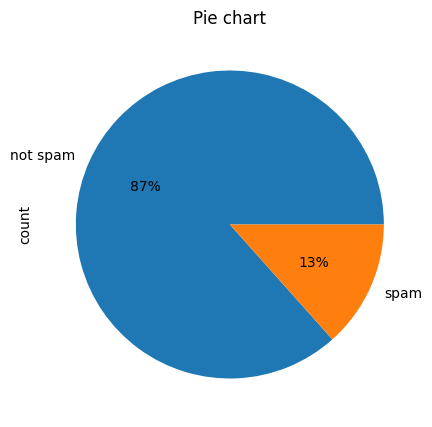

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize = (5, 5))
df['Category'].value_counts().plot(kind = 'pie', autopct='%1.0f%%')
plt.title('Pie chart')

In [ ]:
#exmple model checks mail:
  #  Hi Kavi, are we meeting for python project tomorrow?
  #  Win a free lottery prize now and cash money
  #  your free gift card worth 1000 dollarsClaim
  #  Project submission deadline extended by mam
  #  Congratulations you won a free vacation ticket